# EntregaCerta AI — preparação de dados, passo a passo

## Objetivo

Entender como os CSVs reais da Olist viram uma base para estudar **risco de atraso**
e, depois, **quantos dias um pedido pode atrasar**. Este notebook faz a preparação;
o treinamento dos modelos será outra etapa.

**Roteiro:** 1. Ler → 2. Resumir e juntar → 3. Criar atributos e alvos →
4. Conferir e limpar → 5. Separar pelo tempo → 6. Preparar números → 7. Conferir e salvar.

**Execução conferida em 05/11/2026:** 35 células executadas, 91.390 pedidos preparados,
41.173 no treino, 24.667 na validação e 25.550 no teste. As 29 características originais
viraram 159 atributos numéricos. Essas contagens descrevem a preparação, não desempenho de ML.

Os scripts em `src/` continuam preservados para execução automática. Aqui os cálculos
ficam visíveis, sem chamar esses scripts. Execute uma célula de cada vez e leia a saída.

## Preparação

No VS Code, abra este arquivo e selecione **.venv (Python 3.12)** em **Selecionar Kernel**.
Comece pelo início; se alterar uma célula, reinicie o kernel e execute tudo novamente.
As bibliotecas estão listadas em `requirements.txt`. Não há conexão com API ou banco neste notebook.

**Fonte:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce),
registros reais anonimizados de 2016–2018, licença documentada **CC BY-NC-SA 4.0**.
Os arquivos precisam estar em `Dados/Brazilian Logistic/`.

### Hipóteses e cuidados

- Uma linha final representa **um pedido**, identificado por `order_id`.
- A previsão futura será feita na **aprovação**. Supomos que itens, cadastros, pagamentos e
  prazo prometido já estejam disponíveis. A fonte não tem snapshots para provar toda essa disponibilidade.
- Entrega efetiva e status final só servem para conferir o desfecho. Nunca entram em `X`.
- Pedido sem desfecho conhecido não vira automaticamente um pedido pontual.
- As distâncias são aproximações por prefixo de CEP, em linha geodésica, não percursos rodoviários.
- Este fluxo incorpora a correção geográfica da preparação de ML; não recria byte a byte o CSV consolidado antigo.

### Bibliotecas

`Pandas` trabalha com tabelas; `NumPy`, com números. O Scikit-learn fará apenas as transformações dos atributos nesta etapa.

In [1]:
from pathlib import Path
import hashlib
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("Python:", sys.version.split()[0], "| Pandas:", pd.__version__)
print("NumPy:", np.__version__, "| Scikit-learn:", sklearn.__version__)

Python: 3.12.14 | Pandas: 3.1.0
NumPy: 2.5.4 | Scikit-learn: 1.9.1


### Localizar a pasta

`Path` monta caminhos. Esta célula funciona com o kernel iniciado na raiz do projeto ou na pasta `Notebooks`.

In [2]:
RAIZ = Path.cwd()
if not (RAIZ / "Dados").is_dir():
    RAIZ = RAIZ.parent
ORIGINAIS = RAIZ / "Dados" / "Brazilian Logistic"
assert ORIGINAIS.is_dir(), "Abra o projeto ou a pasta Notebooks antes de executar."
pd.set_option("display.max_columns", 8)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})
print("Pasta dos CSVs:", ORIGINAIS.relative_to(RAIZ))

Pasta dos CSVs: Dados\Brazilian Logistic


## Etapas

## 1. Ler os CSVs originais

Vamos usar sete arquivos. Avaliações de clientes foram escritas após a compra e não
entram na previsão. A tradução das categorias não é necessária para estes cálculos.
Prefixos de CEP são textos: o zero à esquerda precisa ser preservado.

### 1.1. Pedidos, itens, pagamentos e produtos

`read_csv` carrega cada arquivo em um DataFrame, uma tabela em memória.

In [3]:
pedidos = pd.read_csv(ORIGINAIS / "olist_orders_dataset.csv")
itens = pd.read_csv(ORIGINAIS / "olist_order_items_dataset.csv")
pagamentos = pd.read_csv(ORIGINAIS / "olist_order_payments_dataset.csv")
produtos = pd.read_csv(ORIGINAIS / "olist_products_dataset.csv")
pedidos[["order_status", "order_approved_at", "order_estimated_delivery_date"]].head(3)

,order_status,order_approved_at,order_estimated_delivery_date
0,delivered,2017-10-02 11:07:15,2017-10-18 00:00:00
1,delivered,2018-07-26 03:24:27,2018-08-13 00:00:00
2,delivered,2018-08-08 08:55:23,2018-09-04 00:00:00


### 1.2. Clientes, vendedores e geolocalização

Um prefixo de CEP pode ter várias coordenadas. Mais adiante vamos resumi-las pela mediana.

In [4]:
clientes = pd.read_csv(ORIGINAIS / "olist_customers_dataset.csv",
                      dtype={"customer_zip_code_prefix": "string"})
vendedores = pd.read_csv(ORIGINAIS / "olist_sellers_dataset.csv",
                        dtype={"seller_zip_code_prefix": "string"})
geo = pd.read_csv(ORIGINAIS / "olist_geolocation_dataset.csv",
                 dtype={"geolocation_zip_code_prefix": "string"})
clientes["customer_zip_code_prefix"] = clientes["customer_zip_code_prefix"].str.zfill(5)
vendedores["seller_zip_code_prefix"] = vendedores["seller_zip_code_prefix"].str.zfill(5)
geo["geolocation_zip_code_prefix"] = geo["geolocation_zip_code_prefix"].str.zfill(5)

### 1.3. Conferir tamanho e chaves

`assert` interrompe a execução se uma regra for descumprida. Geolocalização repete CEPs por natureza; as demais chaves abaixo precisam ser únicas e preenchidas.

In [5]:
tabelas = {"pedidos": pedidos, "itens": itens, "pagamentos": pagamentos,
           "produtos": produtos, "clientes": clientes, "vendedores": vendedores, "geo": geo}
chaves = {"pedidos": ["order_id"], "itens": ["order_id", "order_item_id"],
          "pagamentos": ["order_id", "payment_sequential"], "produtos": ["product_id"],
          "clientes": ["customer_id"], "vendedores": ["seller_id"]}
for nome, chave in chaves.items():
    assert tabelas[nome][chave].notna().all().all(), f"Chave ausente: {nome}"
    assert not tabelas[nome].duplicated(chave).any(), f"Chave repetida: {nome}"
pd.DataFrame({nome: [len(tabela), len(tabela.columns)] for nome, tabela in tabelas.items()},
             index=["linhas", "colunas"]).T

,linhas,colunas
pedidos,99441,8
itens,112650,7
pagamentos,103886,5
produtos,32951,9
clientes,99441,5
vendedores,3095,4
geo,1000163,5


### 1.4. Conferir relações e converter datas

As relações precisam corresponder aos cadastros. `to_datetime` transforma o texto de uma data em algo com que podemos calcular intervalos.

In [6]:
assert itens["order_id"].isin(pedidos["order_id"]).all()
assert pagamentos["order_id"].isin(pedidos["order_id"]).all()
assert itens["product_id"].isin(produtos["product_id"]).all()
assert itens["seller_id"].isin(vendedores["seller_id"]).all()
assert pedidos["customer_id"].isin(clientes["customer_id"]).all()
assert itens[["price", "freight_value"]].notna().all().all()
assert pagamentos["payment_value"].notna().all()
DATAS = ["order_purchase_timestamp", "order_approved_at",
         "order_delivered_customer_date", "order_estimated_delivery_date"]
for coluna in DATAS:
    pedidos[coluna] = pd.to_datetime(pedidos[coluna], errors="raise")
print("Chaves, relações, valores monetários e formato das datas: OK")

Chaves, relações, valores monetários e formato das datas: OK


## 2. Resumir e juntar as tabelas

**Por que não juntar tudo de uma vez?** Um pedido com vários itens e vários pagamentos
teria linhas multiplicadas. Primeiro somamos itens e pagamentos por pedido; depois usamos `merge`.
`validate` confere se as chaves de cada junção têm a cardinalidade esperada.

### 2.1. Preparar peso, volume e ausências

Valores ausentes ou não positivos não representam medidas confiáveis. Um peso total parcial não deve parecer o peso completo de um pedido.

In [7]:
detalhes = itens.merge(produtos, on="product_id", how="left", validate="many_to_one")
detalhes["peso_valido"] = detalhes["product_weight_g"].where(detalhes["product_weight_g"] > 0)
dimensoes = ["product_length_cm", "product_height_cm", "product_width_cm"]
medidas_validas = detalhes[dimensoes].gt(0).all(axis=1)
detalhes["volume_valido"] = detalhes[dimensoes].prod(axis=1, min_count=3).where(medidas_validas)
detalhes["sem_peso"] = detalhes["peso_valido"].isna().astype(int)
detalhes["sem_dimensoes"] = detalhes["volume_valido"].isna().astype(int)
detalhes["sem_categoria"] = detalhes["product_category_name"].isna().astype(int)
detalhes[["price", "freight_value", "peso_valido", "volume_valido"]].head(3)

,price,freight_value,peso_valido,volume_valido
0,58.9,13.29,650.0,3528.0
1,239.9,19.93,30000.0,60000.0
2,199.0,17.87,3050.0,14157.0


### 2.2. Uma linha por pedido nos itens

`groupby` agrupa linhas do mesmo pedido; `agg` calcula quantidades e totais. O nome à esquerda é a nova coluna; à direita estão a coluna original e o cálculo.

In [8]:
resumo_itens = detalhes.groupby("order_id", as_index=False).agg(
    quantidade_itens=("order_item_id", "size"),
    quantidade_produtos=("product_id", "nunique"),
    quantidade_vendedores=("seller_id", "nunique"),
    quantidade_categorias=("product_category_name", "nunique"),
    valor_itens=("price", "sum"), valor_frete=("freight_value", "sum"),
    peso_total_g=("peso_valido", "sum"), volume_total_cm3=("volume_valido", "sum"),
    itens_sem_peso=("sem_peso", "sum"), itens_sem_dimensoes=("sem_dimensoes", "sum"),
    itens_sem_categoria=("sem_categoria", "sum"))
resumo_itens.loc[resumo_itens["itens_sem_peso"] > 0, "peso_total_g"] = np.nan
resumo_itens.loc[resumo_itens["itens_sem_dimensoes"] > 0, "volume_total_cm3"] = np.nan
print("Pedidos com itens:", len(resumo_itens))

Pedidos com itens: 98666


### 2.3. Categoria principal

Escolhemos a categoria com mais itens no pedido. Em um empate usamos a ordem alfabética, uma regra fixa que não usa o desfecho.

In [9]:
categorias = detalhes.groupby(["order_id", "product_category_name"]).size()
categorias = categorias.rename("itens_categoria").reset_index()
categorias = categorias.sort_values(["order_id", "itens_categoria", "product_category_name"],
                                    ascending=[True, False, True])
principal = categorias.drop_duplicates("order_id")[["order_id", "product_category_name"]]
principal = principal.rename(columns={"product_category_name": "categoria_principal"})
resumo_itens = resumo_itens.merge(principal, on="order_id", how="left", validate="one_to_one")
resumo_itens[["quantidade_itens", "peso_total_g", "categoria_principal"]].head(3)

,quantidade_itens,peso_total_g,categoria_principal
0,1,650.0,cool_stuff
1,1,30000.0,pet_shop
2,1,3050.0,moveis_decoracao


### 2.4. Uma linha por pedido nos pagamentos

Um pedido pode ter mais de uma cobrança ou forma de pagamento. Aqui somamos os valores e contamos as ocorrências.

In [10]:
resumo_pagamentos = pagamentos.groupby("order_id", as_index=False).agg(
    valor_pago=("payment_value", "sum"),
    quantidade_pagamentos=("payment_sequential", "size"),
    quantidade_formas_pagamento=("payment_type", "nunique"),
    parcelas_maximas=("payment_installments", "max"))
por_tipo = pagamentos.groupby(["order_id", "payment_type"], as_index=False)["payment_value"].sum()
por_tipo = por_tipo.sort_values(["order_id", "payment_value", "payment_type"],
                               ascending=[True, False, True])
principal = por_tipo.drop_duplicates("order_id")[["order_id", "payment_type"]]
principal = principal.rename(columns={"payment_type": "tipo_pagamento_principal"})
resumo_pagamentos = resumo_pagamentos.merge(principal, on="order_id", validate="one_to_one")
print("Pedidos com pagamento:", len(resumo_pagamentos))

Pedidos com pagamento: 99440


### 2.5. Coordenadas plausíveis por CEP

Removemos pontos fora de um retângulo conservador do Brasil, incluindo ilhas. Isso não garante exatidão municipal. A mediana resume os pontos reais de cada prefixo, sem inventar coordenadas. [Referência: IBGE](https://anuario.ibge.gov.br/images/aeb/2024/s1/2_pdf/s1t1101.pdf).

In [11]:
plausiveis = geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -28)
coordenadas = geo.loc[plausiveis].groupby("geolocation_zip_code_prefix", as_index=False).agg(
    latitude=("geolocation_lat", "median"), longitude=("geolocation_lng", "median"))
print("Pontos removidos pelo controle geográfico:", int((~plausiveis).sum()))
print("Prefixos com coordenadas aproveitáveis:", len(coordenadas))

Pontos removidos pelo controle geográfico: 31
Prefixos com coordenadas aproveitáveis: 19011


### 2.6. Juntar pedidos e clientes

`left` preserva todos os pedidos mesmo se faltar uma coordenada. A distância ficará desconhecida nesse caso.

In [12]:
destinos = coordenadas.rename(columns={
    "geolocation_zip_code_prefix": "customer_zip_code_prefix",
    "latitude": "lat_cliente", "longitude": "lon_cliente"})
base = pedidos.merge(clientes, on="customer_id", how="left", validate="many_to_one")
base = base.merge(destinos, on="customer_zip_code_prefix", how="left", validate="many_to_one")
assert len(base) == len(pedidos)
print("Pedidos preservados:", len(base))

Pedidos preservados: 99441


### 2.7. Localizar a origem de cada pedido

Cada vendedor aparece uma vez por pedido. Assim a média de distâncias não fica acidentalmente ponderada pelo número de itens.

In [13]:
coordenadas_vendedor = coordenadas.rename(columns={
    "geolocation_zip_code_prefix": "seller_zip_code_prefix",
    "latitude": "lat_vendedor", "longitude": "lon_vendedor"})
origens = itens[["order_id", "seller_id"]].drop_duplicates()
origens = origens.merge(vendedores, on="seller_id", how="left", validate="many_to_one")
origens = origens.merge(coordenadas_vendedor, on="seller_zip_code_prefix",
                        how="left", validate="many_to_one")
origens = origens.merge(base[["order_id", "lat_cliente", "lon_cliente"]],
                        on="order_id", how="left", validate="many_to_one")
print("Pares únicos de pedido e vendedor:", len(origens))

Pares únicos de pedido e vendedor: 100010


### 2.8. Calcular a distância aproximada

Esta é a única função de cálculo criada no notebook. A fórmula de Haversine usa latitude e longitude para medir a distância sobre a esfera terrestre. Não é necessário decorar a fórmula; compreenda as entradas e a unidade em km.

In [14]:
def distancia_km(lat_cliente, lon_cliente, lat_vendedor, lon_vendedor):
    lat1 = np.radians(lat_cliente.astype(float))
    lon1 = np.radians(lon_cliente.astype(float))
    lat2 = np.radians(lat_vendedor.astype(float))
    lon2 = np.radians(lon_vendedor.astype(float))
    a = np.sin((lat2 - lat1) / 2) ** 2
    a += np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

origens["distancia_km"] = distancia_km(origens["lat_cliente"], origens["lon_cliente"],
                                      origens["lat_vendedor"], origens["lon_vendedor"])
origens["sem_distancia"] = origens["distancia_km"].isna().astype(int)
origens["sem_uf"] = origens["seller_state"].isna().astype(int)

### 2.9. Resumir distâncias e estados de origem

Usamos média e maior distância entre os vendedores. Se houver estados diferentes, a origem é `MULTIPLAS`; se faltar UF de algum vendedor, ela fica ausente. Os contadores avisam quando a distância é apenas parcial.

In [15]:
rotas = origens.groupby("order_id", as_index=False).agg(
    quantidade_ufs_origem=("seller_state", "nunique"), uf_origem=("seller_state", "first"),
    vendedores_sem_uf=("sem_uf", "sum"),
    distancia_media_vendedores_km=("distancia_km", "mean"),
    distancia_max_vendedores_km=("distancia_km", "max"),
    vendedores_sem_distancia=("sem_distancia", "sum"))
rotas.loc[rotas["quantidade_ufs_origem"] > 1, "uf_origem"] = "MULTIPLAS"
rotas.loc[rotas["vendedores_sem_uf"] > 0, "uf_origem"] = pd.NA
base = base.merge(resumo_itens, on="order_id", how="left", validate="one_to_one")
base = base.merge(rotas, on="order_id", how="left", validate="one_to_one")
base = base.merge(resumo_pagamentos, on="order_id", how="left", validate="one_to_one")
print("Linhas depois das junções:", len(base))

Linhas depois das junções: 99441


### 2.10. Conferir se valores foram multiplicados

Os totais precisam coincidir com os arquivos de origem. Isso detecta um erro comum de junções: duplicar dinheiro ou itens sem perceber.

In [16]:
assert len(base) == len(pedidos) and base["order_id"].is_unique
assert set(base["order_id"]) == set(pedidos["order_id"])
assert base["quantidade_itens"].sum() == len(itens)
assert base["quantidade_pagamentos"].sum() == len(pagamentos)
totais = pd.DataFrame({
    "originais_R$": [itens["price"].sum(), itens["freight_value"].sum(), pagamentos["payment_value"].sum()],
    "consolidado_R$": [base["valor_itens"].sum(), base["valor_frete"].sum(), base["valor_pago"].sum()]},
    index=["produtos", "frete", "pagamentos"])
np.testing.assert_allclose(totais["originais_R$"], totais["consolidado_R$"], rtol=0, atol=0.005)
totais.round(2)

,originais_R$,consolidado_R$
produtos,13591643.70,13591643.70
frete,2251909.54,2251909.54
pagamentos,16008872.12,16008872.12


## 3. Criar atributos e alvos

**Atributos (`X`)** são informações disponíveis para fazer a previsão.
**Alvo (`y`)** é a resposta observada no histórico que o modelo tentará aprender.
`atrasou`: 0 = entregue no prazo, 1 = entregue após o dia prometido.
`dias_atraso`: diferença positiva em dias de calendário; zero para pedidos pontuais.
Esses dias são observados, não uma estimativa pronta.

### 3.1. Atributos de tempo disponíveis na aprovação

Calculamos o prazo prometido a partir da aprovação e quanto demorou a aprovação. Segunda-feira corresponde a zero. Não usamos o dia da entrega real como entrada.

In [17]:
compra = base["order_purchase_timestamp"]
aprovacao = base["order_approved_at"]
entrega = base["order_delivered_customer_date"]
promessa = base["order_estimated_delivery_date"]
base["prazo_prometido_dias"] = (promessa.dt.normalize() - aprovacao.dt.normalize()).dt.days
base["tempo_aprovacao_horas"] = (aprovacao - compra).dt.total_seconds() / 3600
base["dia_semana_aprovacao"] = aprovacao.dt.day_of_week
base["mes_aprovacao"] = aprovacao.dt.month
base["hora_aprovacao"] = aprovacao.dt.hour
base[["prazo_prometido_dias", "tempo_aprovacao_horas", "dia_semana_aprovacao"]].head(3)

,prazo_prometido_dias,tempo_aprovacao_horas,dia_semana_aprovacao
0,16.0,0.178333,0.0
1,18.0,30.713889,3.0
2,27.0,0.276111,2.0


### 3.2. Alvos calculados com datas reais

`normalize` retira a hora: uma entrega no mesmo dia prometido é pontual. Apenas pedidos entregues com datas observadas e cronologia mínima coerente recebem rótulo; os demais ficam ausentes.

In [18]:
observado = (base["order_status"].eq("delivered") & entrega.notna()
             & promessa.notna() & compra.notna() & entrega.ge(compra))
diferenca_dias = (entrega.dt.normalize() - promessa.dt.normalize()).dt.days
base["atrasou"] = diferenca_dias.gt(0).where(observado).astype("Int64")
base["dias_atraso"] = diferenca_dias.clip(lower=0).where(observado).astype("Int64")
assert base.loc[~observado, ["atrasou", "dias_atraso"]].isna().all().all()
print("Pedidos sem rótulo observado:", int(base["atrasou"].isna().sum()))
base[["order_estimated_delivery_date", "order_delivered_customer_date", "atrasou", "dias_atraso"]].head(4)

Pedidos sem rótulo observado: 2971


,order_estimated_delivery_date,order_delivered_customer_date,atrasou,dias_atraso
0,2017-10-18,2017-10-10 21:25:13,0,0
1,2018-08-13,2018-08-07 15:27:45,0,0
2,2018-09-04,2018-08-17 18:06:29,0,0
3,2017-12-15,2017-12-02 00:28:42,0,0


## 4. Conferir e limpar

Não vamos completar datas nem alvos. Vamos selecionar os registros com desfecho e cronologia
coerentes e tratar problemas dos atributos. A população resultante representa **pedidos entregues**;
não serve para afirmar como seriam cancelamentos ou todos os pedidos em aberto.
Chamaremos esse conjunto selecionado de **coorte**.

### 4.1. Mostrar as exclusões, uma regra por vez

A tabela mostra exclusões sequenciais: um pedido removido por uma regra não volta a ser contado na seguinte. Os originais permanecem intactos.

In [19]:
regras = {"identificador ausente": base["order_id"].notna(),
          "sem status delivered": base["order_status"].eq("delivered"),
          "datas essenciais ausentes": base[DATAS].notna().all(axis=1),
          "aprovação antes da compra": aprovacao.ge(compra),
          "entrega antes da aprovação": entrega.ge(aprovacao),
          "promessa antes do dia da aprovação": promessa.dt.normalize().ge(aprovacao.dt.normalize()),
          "sem itens": base["quantidade_itens"].gt(0)}
aceitos = pd.Series(True, index=base.index)
exclusoes = {}
for motivo, regra in regras.items():
    exclusoes[motivo] = int((aceitos & ~regra.fillna(False)).sum())
    aceitos &= regra.fillna(False)
pd.Series(exclusoes, name="pedidos_excluídos").to_frame()

,pedidos_excluídos
identificador ausente,0
sem status delivered,2963
datas essenciais ausentes,22
aprovação antes da compra,0
entrega antes da aprovação,61
promessa antes do dia da aprovação,1
sem itens,0


### 4.2. Manter a coorte válida

Ordenamos os pedidos pela aprovação. Guardamos a entrega real como o instante conservador em que o rótulo já era conhecido; esse campo fica fora dos atributos.

In [20]:
coorte = base.loc[aceitos].copy()
coorte["atrasou"] = coorte["atrasou"].astype("int8")
coorte["dias_atraso"] = coorte["dias_atraso"].astype("int32")
coorte["rotulo_disponivel_em"] = coorte["order_delivered_customer_date"]
coorte = coorte.sort_values(["order_approved_at", "order_id"]).reset_index(drop=True)
print("Pedidos elegíveis antes da divisão temporal:", len(coorte))
assert coorte[["atrasou", "dias_atraso"]].notna().all().all()

Pedidos elegíveis antes da divisão temporal: 96394


### 4.3. Escolher explicitamente as entradas

Esta lista evita que datas futuras, status final, IDs ou o próprio alvo entrem no modelo por engano. São 29 características originais.

In [21]:
COLUNAS_PREVISAO = [
    "customer_state", "uf_origem", "categoria_principal",
    "quantidade_itens", "quantidade_produtos", "quantidade_vendedores",
    "quantidade_categorias", "quantidade_ufs_origem",
    "valor_itens", "valor_frete", "peso_total_g", "volume_total_cm3",
    "itens_sem_peso", "itens_sem_dimensoes", "itens_sem_categoria",
    "distancia_media_vendedores_km", "distancia_max_vendedores_km",
    "vendedores_sem_distancia", "vendedores_sem_uf",
    "valor_pago", "quantidade_pagamentos", "quantidade_formas_pagamento",
    "parcelas_maximas", "tipo_pagamento_principal", "prazo_prometido_dias",
    "tempo_aprovacao_horas", "dia_semana_aprovacao", "mes_aprovacao", "hora_aprovacao"]
CATEGORICAS = ["customer_state", "uf_origem", "categoria_principal", "tipo_pagamento_principal"]
NUMERICAS = [coluna for coluna in COLUNAS_PREVISAO if coluna not in CATEGORICAS]
x = coorte[COLUNAS_PREVISAO].copy()
print(len(NUMERICAS), "numéricas e", len(CATEGORICAS), "categóricas")

25 numéricas e 4 categóricas


### 4.4. Regras numéricas básicas

Números negativos ou infinitos ficam ausentes. Pesos, volumes e algumas quantidades precisam ser positivos. São regras fixas, sem aprender limites usando o teste.

In [22]:
for coluna in NUMERICAS:
    valores = pd.to_numeric(x[coluna], errors="coerce").astype(float)
    x[coluna] = valores.where(np.isfinite(valores) & valores.ge(0))
positivas = ["peso_total_g", "volume_total_cm3", "quantidade_itens", "quantidade_produtos",
             "quantidade_vendedores", "quantidade_pagamentos", "quantidade_formas_pagamento"]
for coluna in positivas:
    x[coluna] = x[coluna].where(x[coluna].gt(0))
inteiras = [c for c in NUMERICAS if c.startswith(("quantidade_", "itens_sem_", "vendedores_sem_"))]
inteiras += ["parcelas_maximas", "dia_semana_aprovacao", "mes_aprovacao", "hora_aprovacao"]
for coluna in inteiras:
    x[coluna] = x[coluna].where(x[coluna].eq(np.floor(x[coluna])))

### 4.5. Domínios e categorias

UFs usam maiúsculas; categorias e formas de pagamento, minúsculas. Ausente continua ausente por enquanto. Valores extremos válidos são preservados.

In [23]:
limites = {"dia_semana_aprovacao": (0, 6), "mes_aprovacao": (1, 12), "hora_aprovacao": (0, 23),
           "distancia_media_vendedores_km": (0, np.pi * 6371.0088),
           "distancia_max_vendedores_km": (0, np.pi * 6371.0088)}
for coluna, (minimo, maximo) in limites.items():
    x[coluna] = x[coluna].where(x[coluna].between(minimo, maximo))
UFS = set("AC AL AP AM BA CE DF ES GO MA MT MS MG PA PB PR PE PI RJ RN RS RO RR SC SP SE TO".split())
for coluna in CATEGORICAS:
    valores = x[coluna].astype("string").str.strip()
    valores = valores.mask(valores.str.lower().isin(["", "nan", "none", "null"]))
    if coluna in ["customer_state", "uf_origem"]:
        permitidos = UFS | ({"MULTIPLAS"} if coluna == "uf_origem" else set())
        valores = valores.str.upper().where(valores.str.upper().isin(permitidos))
    else:
        valores = valores.str.lower()
    x[coluna] = valores.astype(object).where(valores.notna(), np.nan)

## 5. Separar treino, validação e teste pelo tempo

- **Treino:** aprovação antes de 01/01/2018 e entrega conhecida antes desse corte.
- **Validação:** aprovação de 01/01/2018 a 30/04/2018 e entrega conhecida antes de 01/05/2018.
- **Teste:** aprovação a partir de 01/05/2018, com desfecho observado nesta base histórica.

Os cortes são fixos, anteriores à comparação dos modelos. Não vamos mudá-los para melhorar métricas.
Removemos do treino e da validação rótulos que ainda seriam futuros em seus respectivos cortes.
Isso reduz vazamento, mas pode sub-representar entregas demoradas nas fronteiras dos períodos.

### 5.1. Identificar os períodos

Validação servirá para escolher modelos e limiares. Teste ficará reservado para a avaliação final; as contagens abaixo são apenas uma auditoria da preparação.

In [24]:
CORTE_VALIDACAO = pd.Timestamp("2018-01-01")
CORTE_TESTE = pd.Timestamp("2018-05-01")
coorte[COLUNAS_PREVISAO] = x
coorte["particao"] = "teste"
coorte.loc[coorte["order_approved_at"] < CORTE_TESTE, "particao"] = "validacao"
coorte.loc[coorte["order_approved_at"] < CORTE_VALIDACAO, "particao"] = "treino"
futuro_treino = coorte["particao"].eq("treino") & coorte["rotulo_disponivel_em"].ge(CORTE_VALIDACAO)
futuro_validacao = coorte["particao"].eq("validacao") & coorte["rotulo_disponivel_em"].ge(CORTE_TESTE)
print("Rótulos ainda futuros no treino:", int(futuro_treino.sum()))
print("Rótulos ainda futuros na validação:", int(futuro_validacao.sum()))
dados = coorte.loc[~(futuro_treino | futuro_validacao)].copy()
x = x.loc[dados.index].copy()

Rótulos ainda futuros no treino: 2439
Rótulos ainda futuros na validação: 2565


### 5.2. Conferir os grupos

As taxas são proporções reais de atrasos em cada período, não acurácia de um modelo. Diferenças entre períodos precisam ser consideradas na avaliação futura.

In [25]:
PARTICOES = ["treino", "validacao", "teste"]
resumo = dados.groupby("particao")["atrasou"].agg(pedidos="size", atrasados="sum", proporcao="mean")
resumo = resumo.reindex(PARTICOES)
assert dados["order_id"].is_unique
assert dados.loc[dados["particao"].eq("treino"), "rotulo_disponivel_em"].lt(CORTE_VALIDACAO).all()
assert dados.loc[dados["particao"].eq("validacao"), "rotulo_disponivel_em"].lt(CORTE_TESTE).all()
resumo.assign(percentual_atrasados=(100 * resumo["proporcao"]).round(2)).drop(columns="proporcao")

,pedidos,atrasados,percentual_atrasados
particao,,,
treino,41173,1765,4.29
validacao,24667,2494,10.11
teste,25550,1124,4.40


### 5.3. Visualizar os tamanhos das partições

O gráfico responde quantos pedidos serão usados em cada grupo. O eixo começa em zero e as contagens vêm da tabela calculada acima.

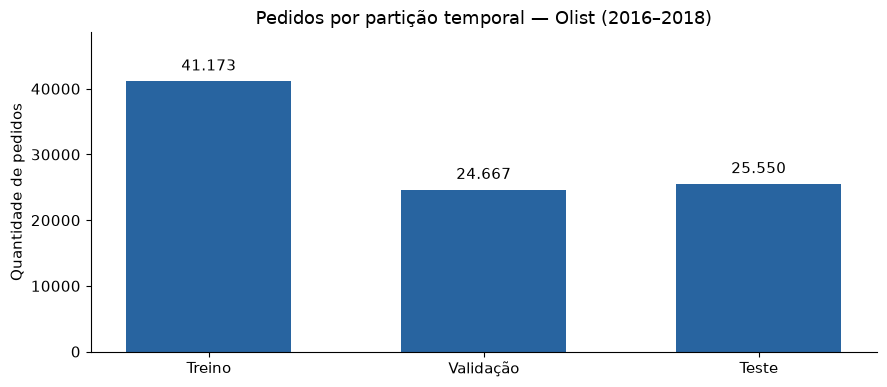

In [26]:
fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.bar(["Treino", "Validação", "Teste"], resumo["pedidos"], color="#2864a0", width=0.6)
ax.bar_label(barras, labels=[f"{n:,}".replace(",", ".") for n in resumo["pedidos"]], padding=5)
ax.set(title="Pedidos por partição temporal — Olist (2016–2018)", ylabel="Quantidade de pedidos")
ax.set_ylim(0, resumo["pedidos"].max() * 1.18)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

A divisão preserva a ordem temporal e a disponibilidade conservadora dos rótulos. Ela não é uma divisão aleatória em percentuais iguais. A coorte é retrospectiva de entregues, com as exclusões mostradas acima.

## 6. Preparar as entradas numéricas

**Mediana:** preenche números ausentes usando somente os pedidos de treino.
**Indicador de ausência:** registra que o valor original estava faltando.
**Padronização:** coloca números em uma escala comparável; não muda os alvos.
**One-hot:** transforma categorias em colunas numéricas.

`fit` aprende os parâmetros. `transform` aplica os parâmetros já aprendidos.
Fazer `fit` na validação ou no teste causaria vazamento.
[Orientação do Scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html).

### 6.1. Ver as ausências do treino

Os valores ainda estão ausentes. Observe que só usamos o treino para esta inspeção e para aprender como preenchê-los.

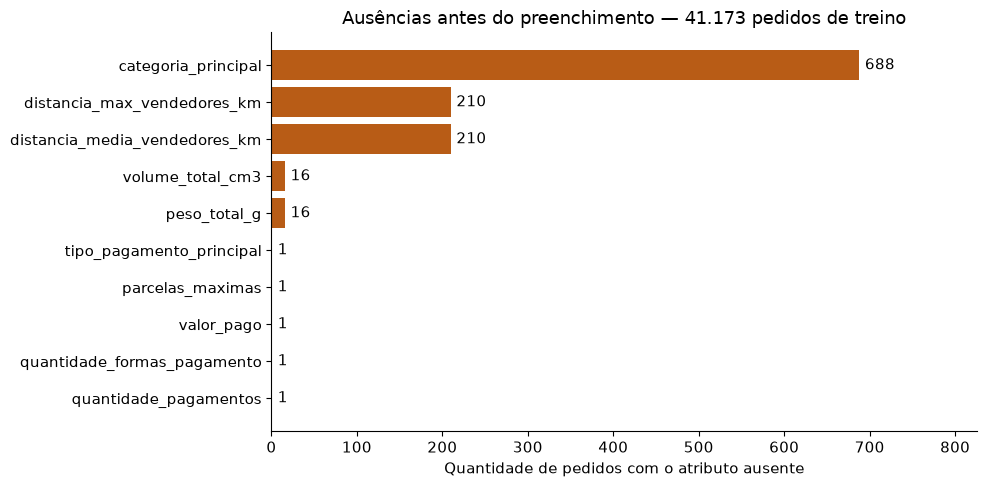

In [27]:
mascara_treino = dados["particao"].eq("treino")
ausencias = x.loc[mascara_treino].isna().sum()
ausencias = ausencias.loc[ausencias > 0].sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.barh(ausencias.index, ausencias.values, color="#b85c16")
ax.bar_label(barras, padding=4)
ax.set(title=f"Ausências antes do preenchimento — {mascara_treino.sum():,} pedidos de treino".replace(",", "."),
       xlabel="Quantidade de pedidos com o atributo ausente")
ax.set_xlim(0, max(ausencias.max(), 1) * 1.2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

A falta de categoria e de distância aparece no próprio histórico. Preencher atributos com uma regra aprendida no treino não cria pedidos novos nem inventa alvos. Os indicadores preservam parte dessa informação de ausência.

### 6.2. Montar as duas sequências de transformação

`Pipeline` executa passos na ordem: preencher e padronizar números; preencher e codificar categorias. Categorias futuras desconhecidas não exigirão novo ajuste.

In [28]:
pipeline_numerico = Pipeline([
    ("imputador", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
    ("escala", StandardScaler())])
pipeline_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="constant", fill_value="NAO_INFORMADO", keep_empty_features=True)),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32))])
preprocessador = ColumnTransformer([
    ("numericas", pipeline_numerico, NUMERICAS),
    ("categoricas", pipeline_categorico, CATEGORICAS)], remainder="drop")
preprocessador.fit(x.loc[mascara_treino]);
print("Transformações ajustadas somente no treino.")

Transformações ajustadas somente no treino.


### 6.3. Criar X e y para cada grupo

`X` contém as matrizes de atributos; `y`, o alvo de classificação; `y_dias_atraso`, a duração observada. Os metadados são guardados separadamente para auditoria.

In [29]:
X, y, y_dias_atraso, metadados = {}, {}, {}, {}
COLUNAS_META = ["order_id", "customer_unique_id", "order_approved_at",
                "rotulo_disponivel_em", "particao", "atrasou", "dias_atraso"]
for nome in PARTICOES:
    mascara = dados["particao"].eq(nome)
    X[nome] = preprocessador.transform(x.loc[mascara]).astype(np.float32)
    y[nome] = dados.loc[mascara, "atrasou"].to_numpy(dtype=np.int8)
    y_dias_atraso[nome] = dados.loc[mascara, "dias_atraso"].to_numpy(dtype=np.int32)
    metadados[nome] = dados.loc[mascara, COLUNAS_META].reset_index(drop=True)
    assert np.isfinite(X[nome]).all(), f"NaN ou infinito em {nome}"
    assert set(y[nome]) == {0, 1}, f"Falta uma classe em {nome}"
    print(nome, "→ X:", X[nome].shape, "| y:", y[nome].shape)

treino → X: (41173, 159) | y: (41173,)


validacao → X: (24667, 159) | y: (24667,)


teste → X: (25550, 159) | y: (25550,)


## 7. Conferir e salvar

Teremos dois formatos: **CSV legível** para inspeção e **Joblib** com matrizes, alvos e
transformações para os modelos. Se os arquivos já existirem, vamos compará-los e preservá-los.
Se não existirem, serão criados. Não criamos cópias duplicadas grandes.

**Atenção:** não passe o CSV inteiro para um estimador: ele contém metadados e alvos.
Para o treinamento futuro, use `X` e `y` do pacote. O CSV já estará preenchido;
reaplicar o preenchimento nele pode perder os indicadores originais de ausência.

### 7.1. CSV legível, sem mudar unidades

Usamos as mesmas medianas aprendidas no treino, mas mantemos reais, gramas, centímetros cúbicos e quilômetros no CSV. Os indicadores `faltante_` mostram o que foi preenchido.

In [30]:
imputador_num = preprocessador.named_transformers_["numericas"].named_steps["imputador"]
imputador_cat = preprocessador.named_transformers_["categoricas"].named_steps["imputador"]
preenchido = x.copy()
for coluna, mediana in zip(NUMERICAS, imputador_num.statistics_):
    preenchido[coluna] = preenchido[coluna].fillna(mediana)
preenchido[CATEGORICAS] = imputador_cat.transform(x[CATEGORICAS])
for indice in imputador_num.indicator_.features_:
    coluna = NUMERICAS[indice]
    preenchido[f"faltante_{coluna}"] = x[coluna].isna().astype("int8")
csv_ml = pd.concat([dados[COLUNAS_META], preenchido], axis=1).reset_index(drop=True)
assert not csv_ml.isna().any().any()
print("CSV preparado em memória:", csv_ml.shape)

CSV preparado em memória: (91390, 44)


### 7.2. Registrar fontes e montar o pacote

O hash é uma impressão digital do arquivo, útil para registrar quais originais foram usados. Ele não mede qualidade ou desempenho. O pacote ainda não contém classificador ou regressor.

In [31]:
arquivos_fonte = [ORIGINAIS / f"olist_{nome}_dataset.csv" for nome in
                  ["orders", "order_items", "order_payments", "products", "customers", "sellers", "geolocation"]]
hashes = {str(p.relative_to(RAIZ)): hashlib.sha256(p.read_bytes()).hexdigest() for p in arquivos_fonte}
pacote = {"preprocessador": preprocessador, "colunas_entrada": COLUNAS_PREVISAO,
          "nomes_atributos": list(preprocessador.get_feature_names_out()),
          "X": X, "y": y, "y_dias_atraso": y_dias_atraso, "metadados": metadados,
          "cortes": {"validacao": str(CORTE_VALIDACAO), "teste": str(CORTE_TESTE)},
          "hashes_entrada": hashes}
CAMINHO_CSV = RAIZ / "Dados" / "pedidos_ml.csv"
CAMINHO_PACOTE = RAIZ / "Modelos" / "dados_ml.joblib"
print("Entradas originais:", len(COLUNAS_PREVISAO), "| Atributos transformados:", X["treino"].shape[1])

Entradas originais: 29 | Atributos transformados: 159


### 7.3. Comparar com o pacote existente

Somente agora abrimos a preparação anterior como referência. Os cálculos acima foram feitos independentemente. Comparamos os pedidos na mesma ordem, os dois alvos e todas as entradas numéricas, com tolerância para arredondamento de ponto flutuante.

In [32]:
if CAMINHO_PACOTE.exists():
    anterior = joblib.load(CAMINHO_PACOTE)
    assert anterior["colunas_entrada"] == pacote["colunas_entrada"]
    assert anterior["nomes_atributos"] == pacote["nomes_atributos"]
    assert anterior["cortes"] == pacote["cortes"]
    for nome in PARTICOES:
        pd.testing.assert_frame_equal(metadados[nome], anterior["metadados"][nome], check_dtype=False)
        np.testing.assert_array_equal(y[nome], anterior["y"][nome])
        np.testing.assert_array_equal(y_dias_atraso[nome], anterior["y_dias_atraso"][nome])
        np.testing.assert_allclose(X[nome], anterior["X"][nome], rtol=1e-5, atol=1e-5)
    print("Pacote existente compatível com o notebook: será preservado.")
else:
    print("O pacote ainda não existe: será criado na próxima conferência.")

Pacote existente compatível com o notebook: será preservado.


### 7.4. Comparar o CSV e gravar somente se necessário

Uma divergência interrompe a execução em vez de substituir silenciosamente os dados. Com arquivos existentes compatíveis, esta célula não os regrava.

In [33]:
if CAMINHO_CSV.exists():
    anterior_csv = pd.read_csv(CAMINHO_CSV, parse_dates=["order_approved_at", "rotulo_disponivel_em"])
    pd.testing.assert_frame_equal(csv_ml, anterior_csv, check_dtype=False, check_exact=False,
                                   rtol=1e-10, atol=1e-7)
    print("CSV existente compatível: preservado.")
if not CAMINHO_CSV.exists():
    csv_ml.to_csv(CAMINHO_CSV, index=False, date_format="%Y-%m-%d %H:%M:%S")
    print("CSV criado:", CAMINHO_CSV.relative_to(RAIZ))
if not CAMINHO_PACOTE.exists():
    CAMINHO_PACOTE.parent.mkdir(exist_ok=True)
    joblib.dump(pacote, CAMINHO_PACOTE, compress=3)
    print("Pacote criado:", CAMINHO_PACOTE.relative_to(RAIZ))

CSV existente compatível: preservado.


## Conferências finais

As matrizes precisam ter tantas linhas quanto os alvos, sem pedidos repetidos entre grupos e sem
valores infinitos ou ausentes. Reabrimos os arquivos para conferir o que ficou salvo.

### Verificar a persistência

São checagens da preparação e da gravação, não métricas de previsão.

In [34]:
salvo = joblib.load(CAMINHO_PACOTE)
salvo_csv = pd.read_csv(CAMINHO_CSV)
assert len(salvo_csv) == len(dados) and salvo_csv["order_id"].is_unique
assert not salvo_csv.isna().any().any()
for nome in PARTICOES:
    assert salvo["X"][nome].shape[0] == len(salvo["y"][nome])
    assert np.isfinite(salvo["X"][nome]).all()
print("Concluído:", len(dados), "pedidos; CSV e pacote conferidos.")
print("Nenhum classificador ou regressor foi treinado.")

Concluído: 91390 pedidos; CSV e pacote conferidos.
Nenhum classificador ou regressor foi treinado.


### Verificar clientes conhecidos

O objetivo futuro é prever novos pedidos ao longo do tempo, incluindo clientes já conhecidos. Esta divisão não mede exclusivamente generalização para clientes novos. IDs ficam fora de `X`.

In [35]:
clientes_treino = set(metadados["treino"]["customer_unique_id"])
for nome in ["validacao", "teste"]:
    conhecidos = metadados[nome]["customer_unique_id"].isin(clientes_treino).sum()
    print(nome, "→ pedidos de clientes que também estão no treino:", conhecidos)
assert "order_id" not in COLUNAS_PREVISAO
assert "customer_unique_id" not in COLUNAS_PREVISAO
assert "order_delivered_customer_date" not in COLUNAS_PREVISAO

validacao → pedidos de clientes que também estão no treino: 367
teste → pedidos de clientes que também estão no treino: 290


## Próximos passos

1. Estudar as saídas e explicar por que agregamos antes das junções, como definimos os alvos
   e por que apenas o treino aprende o preenchimento.
2. Comparar um baseline simples com modelos de classificação usando `X["treino"]` e `y["treino"]`.
   Escolher ajustes e limiar com a validação; reservar o teste para a avaliação final.
3. Avaliar Precision, Recall, F1, matriz de confusão e Average Precision. Accuracy sozinha não basta.
4. Só depois avaliar uma regressão de dias de atraso, com estratégia e métricas próprias.
5. Concluir a EDA relacional e a carga/consulta PostgreSQL, ainda pendentes. Integrar interface e GenAI em suas etapas.

**Limites para o artigo:** os dados são históricos; a seleção de entregues e a remoção de rótulos futuros
mudam a representatividade. Distância por CEP não prova trajeto ou causa do atraso. Ausências podem
carregar vieses de cadastro. O modelo futuro aprenderá associações, não causas comprovadas.
Nenhum ganho operacional, ROI ou desempenho preditivo foi medido aqui.

**Onde consultar:** `Docs/desenvolvimento.md`, `Docs/validacao_dados.txt` e
`Docs/tratamento_ml.txt` preservam metodologia e execuções anteriores.

**Referências técnicas:** [Pandas: junções](https://pandas.pydata.org/docs/user_guide/merging.html),
[Scikit-learn: vazamento de dados](https://scikit-learn.org/stable/common_pitfalls.html),
[SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html),
[OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).